In [1]:
import pandas as pd
import matplotlib.pyplot as plt

bookings_raw = pd.read_csv("hotel_bookings_final_project.csv")

bookings_raw.info()

bookings_raw.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   hotel                        1000 non-null   str    
 1   is_canceled                  1000 non-null   int64  
 2   lead_time                    1000 non-null   int64  
 3   arrival_date_year            1000 non-null   int64  
 4   arrival_date_month           1000 non-null   str    
 5   arrival_date_day_of_month    1000 non-null   int64  
 6   stays_in_weekend_nights      1000 non-null   int64  
 7   stays_in_week_nights         1000 non-null   int64  
 8   adults                       1000 non-null   int64  
 9   children                     1000 non-null   int64  
 10  babies                       1000 non-null   int64  
 11  country                      998 non-null    str    
 12  market_segment               1000 non-null   str    
 13  deposit_type                 1

,is_canceled,lead_time,arrival_date_year,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests
count,1000.00000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.0000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.36600,105.065000,2016.134000,16.13300,0.924000,2.525000,1.8630,0.109000,0.009000,101.210870,0.032000,0.240000,0.060000,0.593000
std,0.48195,106.445476,0.701809,8.96134,0.954534,1.802394,0.5334,0.404082,0.094488,45.716531,0.176088,0.674429,0.237606,0.799994
min,0.00000,0.000000,2015.000000,1.00000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.00000,19.000000,2016.000000,8.00000,0.000000,1.000000,2.0000,0.000000,0.000000,68.575000,0.000000,0.000000,0.000000,0.000000
50%,0.00000,69.500000,2016.000000,16.00000,1.000000,2.000000,2.0000,0.000000,0.000000,94.500000,0.000000,0.000000,0.000000,0.000000
75%,1.00000,157.000000,2017.000000,24.00000,2.000000,3.000000,2.0000,0.000000,0.000000,125.000000,0.000000,0.000000,0.000000,1.000000
max,1.00000,542.000000,2017.000000,31.00000,8.000000,20.000000,6.0000,3.000000,1.000000,304.000000,1.000000,7.000000,1.000000,5.000000


In [2]:
bookings_raw.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,country,market_segment,deposit_type,customer_type,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests
0,City Hotel,1,1,2015,September,30,0,2,1,0,0,PRT,Offline TA/TO,Non Refund,Transient,98.10,1,0,0,0
1,Resort Hotel,1,19,2016,March,19,2,4,2,0,0,PRT,Online TA,No Deposit,Transient,70.17,0,0,0,1
2,Resort Hotel,0,9,2017,August,1,0,4,2,0,0,ESP,Online TA,No Deposit,Transient,193.40,0,0,0,1
3,Resort Hotel,0,110,2016,November,11,0,1,2,0,0,BRA,Online TA,No Deposit,Transient,36.24,0,2,1,0
4,City Hotel,0,329,2017,July,27,0,2,2,0,0,GBR,Online TA,No Deposit,Transient,89.10,0,0,0,1


In [3]:
print("Duplicate rows:", bookings_raw.duplicated().sum())

print("\nMissing values:")
print(bookings_raw.isna().sum())

print("\nRegion labels:", sorted(bookings_raw["hotel"].dropna().unique()))

print("product_category labels:", sorted(bookings_raw["arrival_date_month"].dropna().unique()))

print("customer_type labels:", sorted(bookings_raw["country"].dropna().unique()))

print("returned labels:", sorted(bookings_raw["market_segment"].dropna().unique()))

print("returned labels:", sorted(bookings_raw["deposit_type"].dropna().unique()))

print("returned labels:", sorted(bookings_raw["customer_type"].dropna().unique()))

print("returned labels:", sorted(bookings_raw["arrival_date_month"].dropna().unique()))

invalid_cancelations = bookings_raw.loc[
    bookings_raw["is_canceled"].notna() &
    ~bookings_raw["is_canceled"].isin([0, 1])
]

invalid_lead_times = bookings_raw.loc[
    bookings_raw["lead_time"].notna() &
    ~bookings_raw["lead_time"] < 0
]

invalid_arrival_date_day_of_month = bookings_raw.loc[
    bookings_raw["arrival_date_day_of_month"].notna() &
    ~bookings_raw["arrival_date_day_of_month"].between(1, 31)
]

invalid_stays_in_weekend_nights = bookings_raw.loc[
    bookings_raw["stays_in_weekend_nights"].notna() &
    ~bookings_raw["stays_in_weekend_nights"].between(0, 2)
]

invalid_stays_in_week_nights = bookings_raw.loc[
    bookings_raw["stays_in_week_nights"].notna() &
    ~bookings_raw["stays_in_week_nights"].between(0, 5)
]

invalid_repeated_guests = bookings_raw.loc[
    bookings_raw["is_repeated_guest"].notna() &
    ~bookings_raw["is_repeated_guest"].isin([0, 1])
]

invalid_cancelations["is_canceled"]
invalid_lead_times["lead_time"]
invalid_arrival_date_day_of_month["arrival_date_day_of_month"]
invalid_stays_in_weekend_nights["stays_in_weekend_nights"]
invalid_stays_in_week_nights["stays_in_week_nights"]
invalid_repeated_guests["is_repeated_guest"]



Duplicate rows: 26

Missing values:
hotel                          0
is_canceled                    0
lead_time                      0
arrival_date_year              0
arrival_date_month             0
arrival_date_day_of_month      0
stays_in_weekend_nights        0
stays_in_week_nights           0
adults                         0
children                       0
babies                         0
country                        2
market_segment                 0
deposit_type                   0
customer_type                  0
average_daily_rate             0
is_repeated_guest              0
booking_changes                0
required_car_parking_spaces    0
total_of_special_requests      0
dtype: int64

Region labels: ['City Hotel', 'Resort Hotel']
product_category labels: ['April', 'August', 'December', 'February', 'January', 'July', 'June', 'March', 'May', 'November', 'October', 'September']
customer_type labels: ['AGO', 'ARG', 'ARM', 'AUS', 'AUT', 'BEL', 'BGR', 'BRA', 'CAF', 'CHE', 'CH

Series([], Name: is_repeated_guest, dtype: int64)

Most of the data values are present and the data values seem to be clean. There are only a couple "country" values missing. Since they would not have a big affect on the result, we can simply fill the values with "unknown".
Although, there are 26 duplicate rows, it does not seem like it will couse any problems, because none of the data values need to be unique.

In [4]:
bookings = bookings_raw

bookings["country"] = bookings["country"].fillna("Unknown")

print("\nMissing values:")
print(bookings.isna().sum())


Missing values:
hotel                          0
is_canceled                    0
lead_time                      0
arrival_date_year              0
arrival_date_month             0
arrival_date_day_of_month      0
stays_in_weekend_nights        0
stays_in_week_nights           0
adults                         0
children                       0
babies                         0
country                        0
market_segment                 0
deposit_type                   0
customer_type                  0
average_daily_rate             0
is_repeated_guest              0
booking_changes                0
required_car_parking_spaces    0
total_of_special_requests      0
dtype: int64


# Ruhan's Part 👇


In [5]:
bookings_b = bookings.copy()

### Total Staying Nights

In [6]:

bookings_b["total_nights"] = (
    bookings_b["stays_in_weekend_nights"]
    + bookings_b["stays_in_week_nights"]
)

bookings_b[[
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "total_nights"
]].head()

,stays_in_weekend_nights,stays_in_week_nights,total_nights
0,0,2,2
1,2,4,6
2,0,4,4
3,0,1,1
4,0,2,2


---------------------------------------------------------------------------------------------------------

### Total Guests

In [7]:
bookings_b["total_guests"] = (
    bookings_b["adults"]
    + bookings_b["children"]
    + bookings_b["babies"]
)

bookings_b[["adults", "children", "babies", "total_guests"]].head()

,adults,children,babies,total_guests
0,1,0,0,1
1,2,0,0,2
2,2,0,0,2
3,2,0,0,2
4,2,0,0,2


---------------------------------------------------------------------------------------------------------

### How much does each booking cost?

In [8]:
bookings_b["estimated_booking_value"] = (
    bookings_b["average_daily_rate"]
    * bookings_b["total_nights"]
)

bookings_b[[
    "average_daily_rate",
    "total_nights",
    "estimated_booking_value"
]].head()

,average_daily_rate,total_nights,estimated_booking_value
0,98.10,2,196.20
1,70.17,6,421.02
2,193.40,4,773.60
3,36.24,1,36.24
4,89.10,2,178.20


---------------------------------------------------------------------------------------------------------

### Guest arrival dates

In [9]:
bookings_b["arrival_date"] = pd.to_datetime(
    bookings_b["arrival_date_year"].astype("string") + "-"
    + bookings_b["arrival_date_month"] + "-"
    + bookings_b["arrival_date_day_of_month"].astype("string"),
    format="%Y-%B-%d",
    errors="coerce"
)

bookings_b[[
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_day_of_month",
    "arrival_date"
]].head()

,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,September,30,2015-09-30
1,2016,March,19,2016-03-19
2,2017,August,1,2017-08-01
3,2016,November,11,2016-11-11
4,2017,July,27,2017-07-27


---------------------------------------------------------------------------------------------------------

## Summary

In [10]:
bookings_b["total_nights"].describe().round(2)

count    1000.00
mean        3.45
std         2.38
min         0.00
25%         2.00
50%         3.00
75%         4.00
max        28.00
Name: total_nights, dtype: float64

##### zero-night bookings

In [11]:
zero_nights = bookings_b.loc[
    bookings_b["total_nights"] == 0
]

print("Zero-night bookings:", len(zero_nights))
zero_nights.head()

Zero-night bookings: 5


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,customer_type,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests,total_nights,total_guests,estimated_booking_value,arrival_date
201,City Hotel,0,0,2017,January,30,0,0,0,0,...,Transient,0.0,1,0,0,0,0,0,0.0,2017-01-30
455,Resort Hotel,0,17,2016,October,10,0,0,1,0,...,Transient-Party,0.0,0,0,0,0,0,1,0.0,2016-10-10
461,City Hotel,0,0,2016,May,17,0,0,1,0,...,Transient,0.0,1,0,0,0,0,1,0.0,2016-05-17
774,City Hotel,0,51,2017,March,8,0,0,0,0,...,Transient,0.0,0,1,0,0,0,0,0.0,2017-03-08
993,City Hotel,0,7,2017,February,13,0,0,0,0,...,Transient,0.0,0,1,0,1,0,0,0.0,2017-02-13


##### stay analysis

In [12]:
overnight_bookings = bookings_b.loc[
    bookings_b["total_nights"] > 0
].copy()

overnight_bookings["total_nights"].describe().round(2)

count    995.00
mean       3.47
std        2.37
min        1.00
25%        2.00
50%        3.00
75%        4.00
max       28.00
Name: total_nights, dtype: float64

##### Stay length distribution

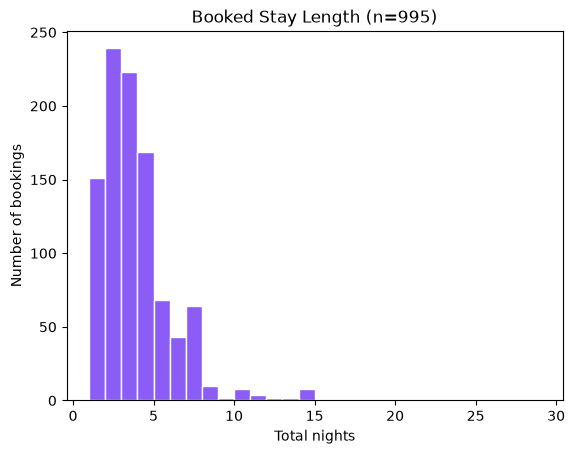

In [13]:
fig, ax = plt.subplots()

ax.hist(
    overnight_bookings["total_nights"],
    bins=range(1, 30),
    color="#8b5cf6",
    edgecolor="white"
)

ax.set_title(f"Booked Stay Length (n={len(overnight_bookings)})")
ax.set_xlabel("Total nights")
ax.set_ylabel("Number of bookings")

plt.show()

##### **What can we observe?**

Most bookings are for 1–4 nights, while longer bookings are less common.
The average booked stay is 3.47 nights and the median is 3 nights.
Five zero-night bookings were excluded. This chart includes both
cancelled and non-cancelled bookings.

_________________________________________________________________________________________________________

### Checking the calculations 👍

In [14]:
print("Total nights correct:", (
    bookings_b["total_nights"] ==
    bookings_b["stays_in_weekend_nights"] + bookings_b["stays_in_week_nights"]
).all())

print("Total guests correct:", (
    bookings_b["total_guests"] ==
    bookings_b["adults"] + bookings_b["children"] + bookings_b["babies"]
).all())

print("Booking values correct:", (
    bookings_b["estimated_booking_value"] ==
    bookings_b["average_daily_rate"] * bookings_b["total_nights"]
).all())

print("Missing or invalid arrival dates:",
      bookings_b["arrival_date"].isna().sum())

Total nights correct: True
Total guests correct: True
Booking values correct: True
Missing or invalid arrival dates: 0


---------------------------------------------------------------------------------------------------------

# Exporting the Results 

In [15]:

bookings_b.to_csv("hotel_bookings_cleaned.csv", index=False)

stay_summary = (
    overnight_bookings["total_nights"]
    .describe()
    .round(2)
    .reset_index()
)

stay_summary.columns = ["statistic", "total_nights"]

stay_summary.to_csv("hotel_booking_summary.csv", index=False)

## Verifying Exports

In [16]:
loaded_bookings = pd.read_csv(
    "hotel_bookings_cleaned.csv",
    parse_dates=["arrival_date"]
)
loaded_summary = pd.read_csv("hotel_booking_summary.csv")

print("Dataset shape matches:", loaded_bookings.shape == bookings_b.shape)
print("Dataset columns match:",
      loaded_bookings.columns.tolist() == bookings_b.columns.tolist())

print("Summary shape matches:", loaded_summary.shape == stay_summary.shape)
print("Summary columns match:",
      loaded_summary.columns.tolist() == stay_summary.columns.tolist())

loaded_summary

Dataset shape matches: True
Dataset columns match: True
Summary shape matches: True
Summary columns match: True


,statistic,total_nights
0,count,995.00
1,mean,3.47
2,std,2.37
3,min,1.00
4,25%,2.00
5,50%,3.00
6,75%,4.00
7,max,28.00


---------------------------------------------------------------------------------------------------------